# Кластерный анализ в Python

**Дисциплина:** Введение в анализ больших данных

**Кластеризация** — разбиение объектов на группы так, чтобы внутри группы объекты были похожи, а между группами — различались.

Методы:
1. **Иерархические** — дендрограмма, `linkage` + `fcluster`
2. **Нейерархические** — k-means (число кластеров задаётся заранее)

Перед кластеризацией признаки обычно **стандартизируют**.

Демо: **penguins** (морфометрия).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")
np.random.seed(42)


---
## 1. Данные и стандартизация


In [2]:
peng = sns.load_dataset("penguins").dropna()
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X = peng[features].copy()
print(X.describe().round(1))


       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           333.0          333.0              333.0        333.0
mean             44.0           17.2              201.0       4207.1
std               5.5            2.0               14.0        805.2
min              32.1           13.1              172.0       2700.0
25%              39.5           15.6              190.0       3550.0
50%              44.5           17.3              197.0       4050.0
75%              48.6           18.7              213.0       4775.0
max              59.6           21.5              231.0       6300.0


In [3]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=features,
    index=X.index,
)
print(X_scaled.head().round(3))
print("средние ≈ 0:", X_scaled.mean().round(3).tolist())
print("ст.откл. ≈ 1:", X_scaled.std(ddof=0).round(3).tolist())


   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0          -0.896          0.781             -1.427       -0.568
1          -0.823          0.120             -1.069       -0.506
2          -0.676          0.425             -0.426       -1.190
4          -1.336          1.086             -0.569       -0.942
5          -0.859          1.747             -0.784       -0.693
средние ≈ 0: [0.0, 0.0, 0.0, -0.0]
ст.откл. ≈ 1: [1.0, 1.0, 1.0, 1.0]


---
## 2. Иерархическая кластеризация

`linkage(X, method="ward")` → дендрограмма → `fcluster(..., criterion="maxclust")`.


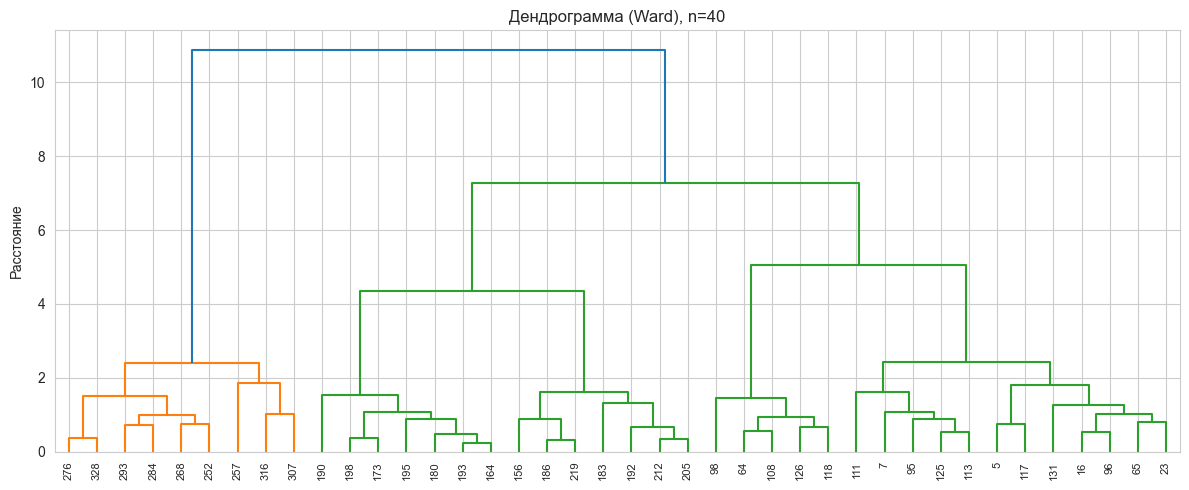

In [4]:
idx = X_scaled.sample(40, random_state=1).index
Xs = X_scaled.loc[idx]
Z = linkage(Xs, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, labels=Xs.index.astype(str).tolist(), leaf_rotation=90, leaf_font_size=8)
plt.title("Дендрограмма (Ward), n=40")
plt.ylabel("Расстояние")
plt.tight_layout()
plt.show()


In [5]:
Z_full = linkage(X_scaled, method="ward")
labels_h = fcluster(Z_full, t=3, criterion="maxclust")
peng_h = peng.copy()
peng_h["cluster_h"] = labels_h
print("Размеры кластеров:")
print(peng_h["cluster_h"].value_counts().sort_index())
print("\nСредние признаков по кластерам:")
print(peng_h.groupby("cluster_h")[features].mean().round(1))


Размеры кластеров:
cluster_h
1    119
2     57
3    157
Name: count, dtype: int64

Средние признаков по кластерам:
           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
cluster_h                                                               
1                    47.6           15.0              217.2       5092.4
2                    49.8           18.6              197.1       3810.1
3                    39.2           18.3              190.0       3680.1


---
## 3. K-means

Число кластеров: **elbow** (inertia) и **silhouette**.


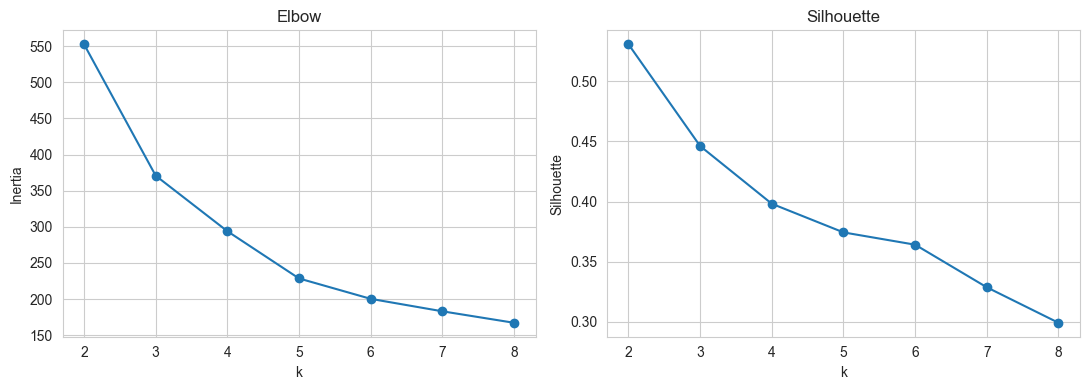

In [6]:
inertias, silhouettes = [], []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, lab))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(K_range), inertias, "o-")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow")
axes[1].plot(list(K_range), silhouettes, "o-")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette"); axes[1].set_title("Silhouette")
plt.tight_layout()
plt.show()


In [7]:
k_opt = 3
km = KMeans(n_clusters=k_opt, n_init=25, random_state=42)
labels_km = km.fit_predict(X_scaled)

peng_km = peng.copy()
peng_km["cluster"] = labels_km + 1
print("Размеры:", peng_km["cluster"].value_counts().sort_index().to_dict())
print("\nЦентры (в стандартизированных координатах):")
print(pd.DataFrame(km.cluster_centers_, columns=features).round(3))
print("\nСредние в исходных единицах:")
print(peng_km.groupby("cluster")[features].mean().round(1))


Размеры: {1: 129, 2: 119, 3: 85}

Центры (в стандартизированных координатах):
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0          -1.047          0.487             -0.882       -0.763
1           0.655         -1.103              1.162        1.101
2           0.672          0.805             -0.289       -0.384

Средние в исходных единицах:
         bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
cluster                                                               
1                  38.3           18.1              188.6       3593.8
2                  47.6           15.0              217.2       5092.4
3                  47.7           18.7              196.9       3898.2


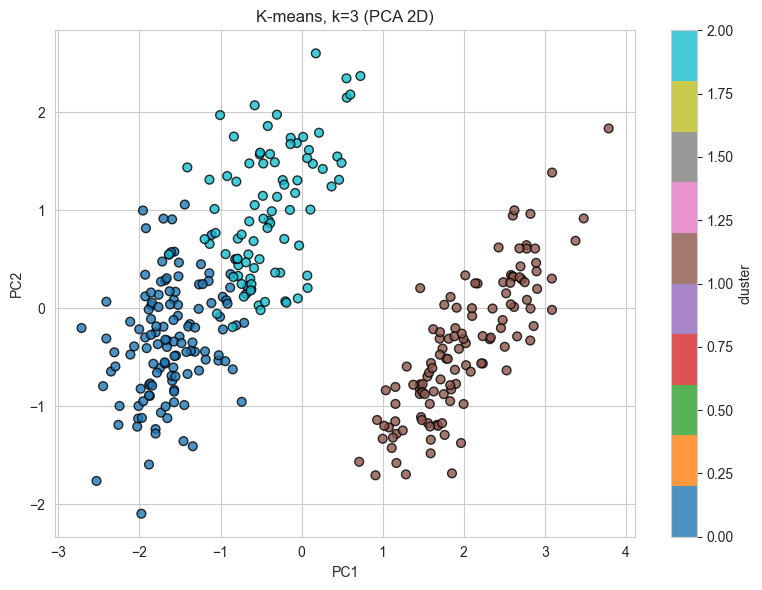

Доля дисперсии PC1+PC2: 0.881


In [8]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sc = plt.scatter(coords[:, 0], coords[:, 1], c=labels_km, cmap="tab10",
                 s=40, edgecolors="k", alpha=0.8)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"K-means, k={k_opt} (PCA 2D)")
plt.colorbar(sc, label="cluster")
plt.tight_layout()
plt.show()
print("Доля дисперсии PC1+PC2:", round(pca.explained_variance_ratio_.sum(), 3))


### Сравнение с известными видами (только для иллюстрации)

В реальном задании «истинных» меток нет — здесь смотрим, насколько кластеры совпадают с `species`.


cluster      1    2   3
species                
Adelie     124    0  22
Chinstrap    5    0  63
Gentoo       0  119   0


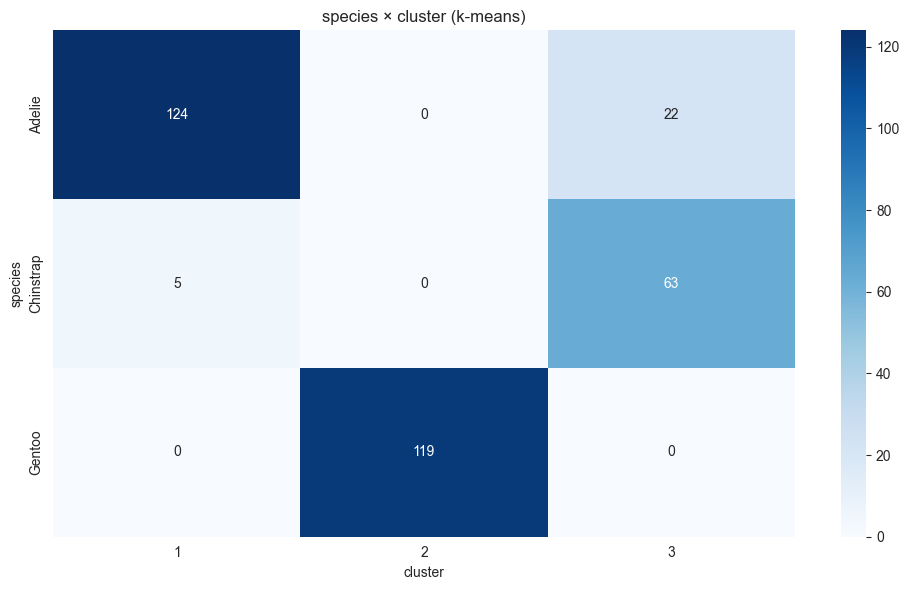

In [9]:
ct = pd.crosstab(peng_km["species"], peng_km["cluster"])
print(ct)
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("species × cluster (k-means)")
plt.tight_layout()
plt.show()


### Как описать результаты

1. Обоснуйте число кластеров (дендрограмма / elbow / silhouette).  
2. Опишите **профили** кластеров (средние признаков).  
3. При необходимости визуализируйте в PCA-плоскости.

---
## Шпаргалка по методам (Python)

| Задача | Код |
|--------|-----|
| Стандартизация | `StandardScaler().fit_transform(X)` |
| Иерархия | `linkage(X, method="ward")` |
| Дендрограмма | `dendrogram(Z, labels=...)` |
| Срез на k групп | `fcluster(Z, t=k, criterion="maxclust")` |
| K-means | `KMeans(n_clusters=k, n_init=10).fit(X)` |
| Метки / центры | `km.labels_`, `km.cluster_centers_` |
| Inertia | `km.inertia_` |
| Silhouette | `silhouette_score(X, labels)` |

---
## Что сделать после лекции

1. Откройте лабораторное задание и выполните кластеризацию **самостоятельно**.  
2. Всегда стандартизируйте признаки перед расчётом расстояний.

Удачи!


In [10]:
import os
from google.colab import files

print("Доступные файлы в рабочей директории:")
print(os.listdir())

uploaded = files.upload()
file_name = next(iter(uploaded))

if file_name.endswith('.csv'):
    data = pd.read_csv(file_name)
elif file_name.endswith('.xlsx'):
    data = pd.read_excel(file_name)
else:
    raise ValueError("Формат файла не поддерживается. Используйте CSV или Excel.")

print(f"\nФайл '{file_name}' успешно загружен!")
data.to_excel('data.xlsx')

ModuleNotFoundError: No module named 'google'